# Question 1

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.data_loader import load_question
from src.model import FlexibleConsumerModel
from src.model import QuadraticDeviationModel
from src.plotting import plot_duals, plot_inputs, plot_schedule

RESULTS_DIR = Path("results")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

from dataclasses import replace

Q2C_RESULTS_DIR = Path("results") / "Q2_quadratic"
Q2C_RESULTS_DIR.mkdir(parents=True, exist_ok=True)


## Question 1(e): Model implementation and result extraction

Import the shared model, data-loading, and plotting utilities used by the implementation.

In [2]:
def run_question_1_case(case_name):
    """Run one Q1 base case and display/save all required outputs."""
    data = load_question(case_name)
    results = FlexibleConsumerModel(data).build().solve()
    hourly = results.hourly.copy()

    # Effective grid prices.
    hourly["effective_import_price"] = data.energy_price + data.import_tariff
    hourly["effective_export_price"] = data.energy_price - data.export_tariff

    # Quantities used in the report.
    hourly["pv_curtailed"] = hourly["pv_available"] - hourly["pv"]
    hourly["net_grid_import"] = hourly["import"] - hourly["export"]
    hourly["balance_residual"] = (
        hourly["import"] + hourly["pv"]
        - hourly["load"] - hourly["export"]
    )

    # Separate economic components required in Q1(e).
    hourly["import_cost"] = (
        hourly["effective_import_price"] * hourly["import"]
    )
    hourly["export_revenue"] = (
        hourly["effective_export_price"] * hourly["export"]
    )
    hourly["pv_production_cost"] = data.pv_marginal_cost * hourly["pv"]
    hourly["consumption_utility"] = data.consumption_utility * hourly["load"]
    hourly["procurement_cost"] = (
        hourly["import_cost"]
        + hourly["pv_production_cost"]
        - hourly["export_revenue"]
    )
    hourly["net_surplus"] = (
        hourly["consumption_utility"] - hourly["procurement_cost"]
    )
    hourly["objective_contribution"] = -hourly["net_surplus"]

    summary = pd.Series(
        {
            "status": results.status,
            "minimized objective [DKK]": results.objective,
            "import cost [DKK]": hourly["import_cost"].sum(),
            "export revenue [DKK]": hourly["export_revenue"].sum(),
            "PV production cost [DKK]": hourly["pv_production_cost"].sum(),
            "procurement cost [DKK]": hourly["procurement_cost"].sum(),
            "consumption utility [DKK]": hourly["consumption_utility"].sum(),
            "net surplus [DKK]": hourly["net_surplus"].sum(),
            "import [kWh]": hourly["import"].sum(),
            "export [kWh]": hourly["export"].sum(),
            "load [kWh]": hourly["load"].sum(),
            "PV available [kWh]": hourly["pv_available"].sum(),
            "PV produced [kWh]": hourly["pv"].sum(),
            "PV curtailed [kWh]": hourly["pv_curtailed"].sum(),
        },
        name=case_name,
    )

    # Basic consistency checks.
    assert np.isclose(
        hourly["objective_contribution"].sum(),
        results.objective,
        atol=1e-6,
    )
    assert hourly["balance_residual"].abs().max() <= 1e-6
    assert not (
        (hourly["import"] > 1e-7) & (hourly["export"] > 1e-7)
    ).any()

    output_folder = RESULTS_DIR / case_name
    output_folder.mkdir(parents=True, exist_ok=True)

    # Use the save and plotting functions already provided by the project.
    results.save(output_folder)
    hourly.to_csv(
        output_folder / f"{case_name}_report_table.csv",
        index_label="hour",
    )
    summary.to_csv(output_folder / f"{case_name}_economic_summary.csv")

    plot_inputs(data, save_to=output_folder / "inputs.png")
    plot_schedule(results, data, save_to=output_folder / "schedule.png")
    plot_duals(results, data, save_to=output_folder / "duals.png")

    print("\n" + "=" * 80)
    print(case_name)
    print("=" * 80)
    print(data.summary())
    print("\nEconomic and energy summary")
    display(summary.to_frame("value").round(4))

    dual_columns = [
        column for column in hourly.columns if column.startswith("dual_")
    ]
    report_columns = [
        "price",
        "effective_import_price",
        "effective_export_price",
        "pv_available",
        "import",
        "export",
        "load",
        "pv",
        "pv_curtailed",
    ] + dual_columns

    print("\nHourly primal and dual results")
    display(hourly[report_columns].round(4))
    plt.show()

    return {
        "data": data,
        "results": results,
        "hourly": hourly,
        "summary": summary,
    }


## Question 1(f): Numerical validation of base cases A and B

Run the two provided base cases and compare their primal schedules, economic quantities, and dual variables.

Set parameter Username
Set parameter LicenseID to value 2861720
Academic license - for non-commercial use only - expires 2027-09-09

Q1_caseA
Case                 : Q1_caseA
Consumer             : C_01_A
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : 1.43
Min daily energy     : None
Reference profile    : no
Disutility lin/quad  : None / None
Battery              : no
Next-day forecasts   : yes

Economic and energy summary


,value
status,OPTIMAL
minimized objective [DKK],-2.6088
import cost [DKK],16.5
export revenue [DKK],5.7
PV production cost [DKK],37.9854
procurement cost [DKK],48.7854
consumption utility [DKK],51.3942
net surplus [DKK],2.6088
import [kWh],12.0
export [kWh],3.0



Hourly primal and dual results


,price,effective_import_price,effective_export_price,pv_available,import,export,load,pv,pv_curtailed,dual_balance,dual_import,dual_export,dual_pv,dual_pv_limit,dual_load_min,dual_load_max
hour,,,,,,,,,,,,,,,,
0,1.10,1.60,0.70,0.00,0.0,0.0,0.00,0.00,0.0,1.60,0.00,0.90,0.00,-0.19,0.17,0.00
1,1.05,1.55,0.65,0.00,0.0,0.0,0.00,0.00,0.0,1.55,0.00,0.90,0.00,-0.14,0.12,0.00
2,1.00,1.50,0.60,0.00,0.0,0.0,0.00,0.00,0.0,1.50,0.00,0.90,0.00,-0.09,0.07,0.00
3,0.90,1.40,0.50,0.00,6.0,0.0,6.00,0.00,0.0,1.40,0.00,0.90,0.01,0.00,0.00,-0.03
4,0.85,1.35,0.45,0.00,6.0,0.0,6.00,0.00,0.0,1.35,0.00,0.90,0.06,0.00,0.00,-0.08
5,1.01,1.51,0.61,0.30,0.0,0.0,0.30,0.30,0.0,1.43,0.08,0.82,0.00,-0.02,0.00,0.00
6,1.05,1.55,0.65,0.84,0.0,0.0,0.84,0.84,0.0,1.43,0.12,0.78,0.00,-0.02,0.00,0.00
7,1.20,1.70,0.80,1.26,0.0,0.0,1.26,1.26,0.0,1.43,0.27,0.63,0.00,-0.02,0.00,0.00
8,1.40,1.90,1.00,0.90,0.0,0.0,0.90,0.90,0.0,1.43,0.47,0.43,0.00,-0.02,0.00,0.00


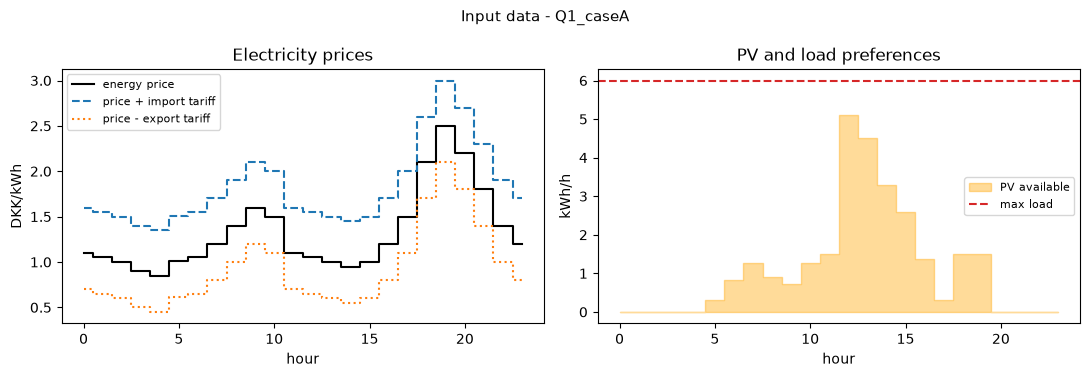

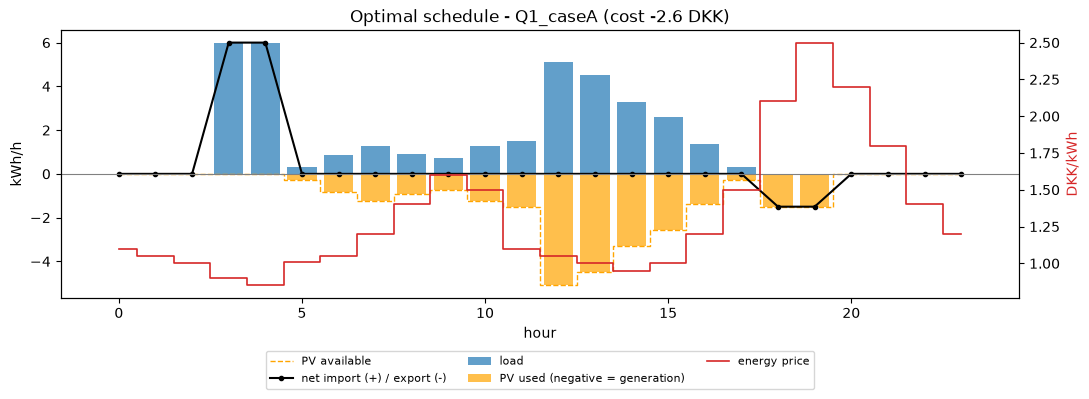

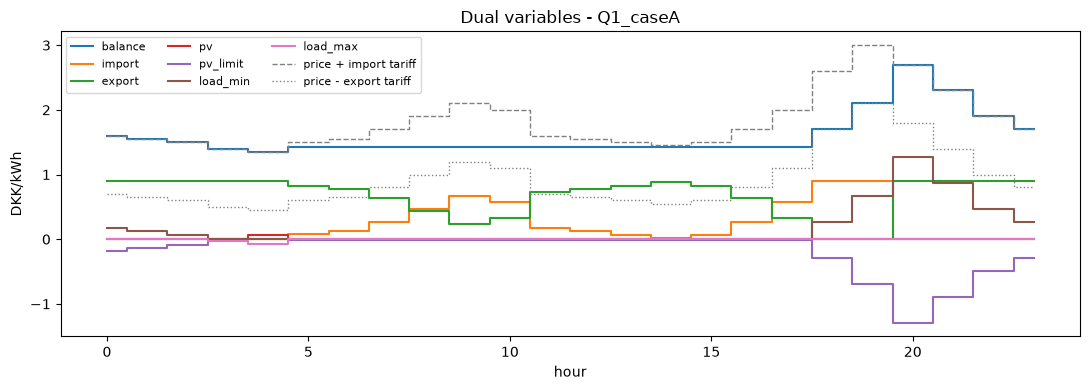


Q1_caseB
Case                 : Q1_caseB
Consumer             : C_01_B
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.47 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : 1.43
Min daily energy     : None
Reference profile    : no
Disutility lin/quad  : None / None
Battery              : no
Next-day forecasts   : yes

Economic and energy summary


,value
status,OPTIMAL
minimized objective [DKK],-1.95
import cost [DKK],16.5
export revenue [DKK],5.7
PV production cost [DKK],4.41
procurement cost [DKK],15.21
consumption utility [DKK],17.16
net surplus [DKK],1.95
import [kWh],12.0
export [kWh],3.0



Hourly primal and dual results


,price,effective_import_price,effective_export_price,pv_available,import,export,load,pv,pv_curtailed,dual_balance,dual_import,dual_export,dual_pv,dual_pv_limit,dual_load_min,dual_load_max
hour,,,,,,,,,,,,,,,,
0,1.10,1.60,0.70,0.00,0.0,0.0,0.0,0.0,0.00,1.60,0.00,0.90,0.00,-0.13,0.17,0.00
1,1.05,1.55,0.65,0.00,0.0,0.0,0.0,0.0,0.00,1.55,0.00,0.90,0.00,-0.08,0.12,0.00
2,1.00,1.50,0.60,0.00,0.0,0.0,0.0,0.0,0.00,1.50,0.00,0.90,0.00,-0.03,0.07,0.00
3,0.90,1.40,0.50,0.00,6.0,0.0,6.0,0.0,0.00,1.40,0.00,0.90,0.07,0.00,0.00,-0.03
4,0.85,1.35,0.45,0.00,6.0,0.0,6.0,0.0,0.00,1.35,0.00,0.90,0.12,0.00,0.00,-0.08
5,1.01,1.51,0.61,0.30,0.0,0.0,0.0,0.0,0.30,1.43,0.08,0.82,0.04,0.00,0.00,0.00
6,1.05,1.55,0.65,0.84,0.0,0.0,0.0,0.0,0.84,1.43,0.12,0.78,0.04,0.00,0.00,0.00
7,1.20,1.70,0.80,1.26,0.0,0.0,0.0,0.0,1.26,1.43,0.27,0.63,0.04,0.00,0.00,0.00
8,1.40,1.90,1.00,0.90,0.0,0.0,0.0,0.0,0.90,1.43,0.47,0.43,0.04,0.00,0.00,0.00


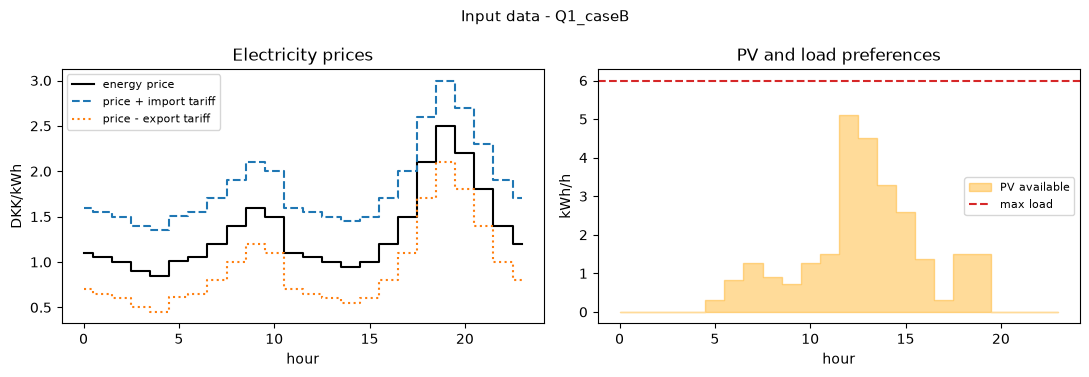

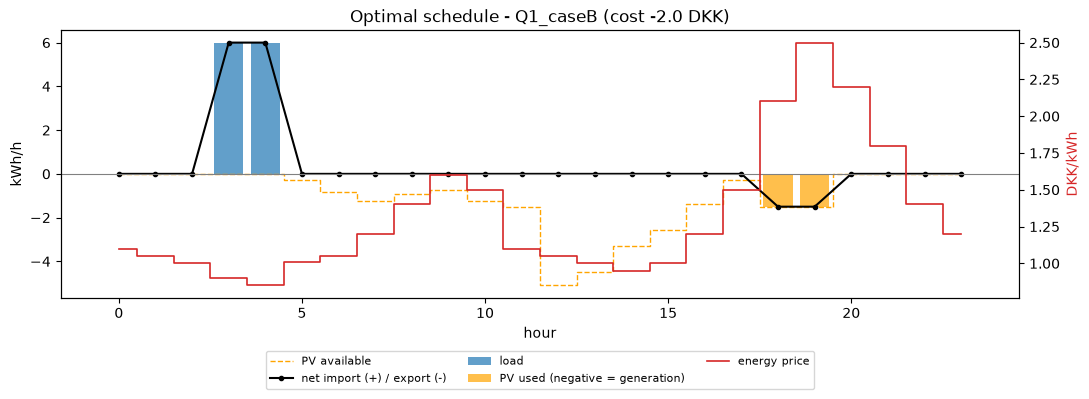

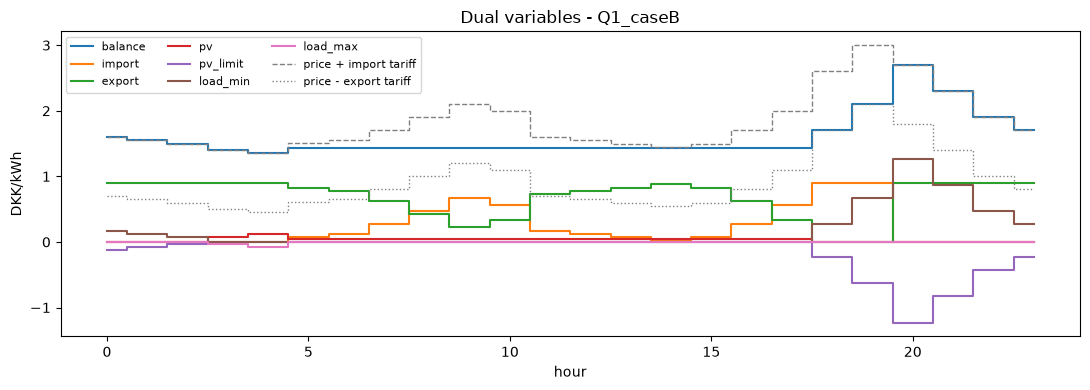

In [3]:
case_a = run_question_1_case("Q1_caseA")
case_b = run_question_1_case("Q1_caseB")


In [4]:
comparison = pd.DataFrame(
    [
        case_a["summary"].to_dict(),
        case_b["summary"].to_dict(),
    ],
    index=["Q1_caseA", "Q1_caseB"],
)
comparison.index.name = "case"

print("Case A and Case B comparison")
display(comparison.round(4))
comparison.to_csv(RESULTS_DIR / "Q1_case_comparison.csv")


Case A and Case B comparison


,status,minimized objective [DKK],import cost [DKK],export revenue [DKK],PV production cost [DKK],procurement cost [DKK],consumption utility [DKK],net surplus [DKK],import [kWh],export [kWh],load [kWh],PV available [kWh],PV produced [kWh],PV curtailed [kWh]
case,,,,,,,,,,,,,,
Q1_caseA,OPTIMAL,-2.6088,16.5,5.7,37.9854,48.7854,51.3942,2.6088,12.0,3.0,35.94,26.94,26.94,0.00
Q1_caseB,OPTIMAL,-1.9500,16.5,5.7,4.4100,15.2100,17.1600,1.9500,12.0,3.0,12.00,26.94,3.00,23.94


# Optional

Case                 : Q1_caseA
Consumer             : C_01_A
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : 1.43
Min daily energy     : None
Reference profile    : no
Disutility lin/quad  : None / None
Battery              : no
Next-day forecasts   : yes
status: OPTIMAL | objective: -2.61 DKK
daily totals (kWh): import=12.0, export=3.0, load=35.9, pv=26.9


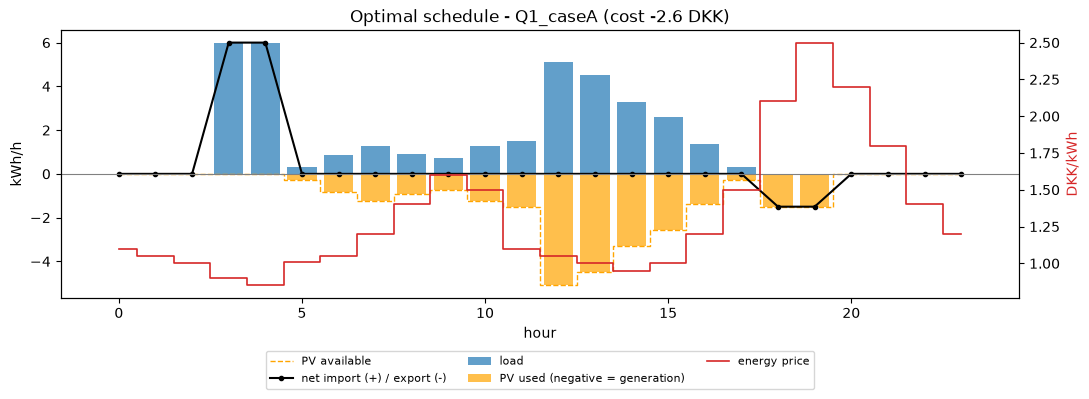

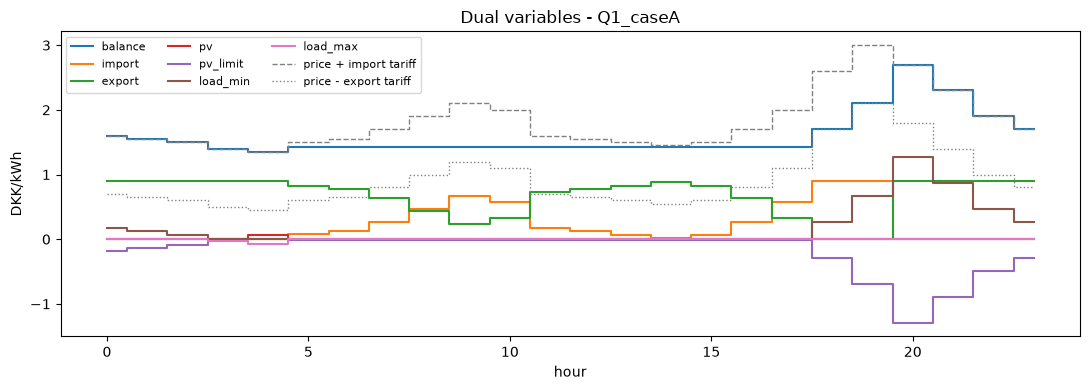

In [5]:
from src.data_loader import load_question
from src.model import FlexibleConsumerModel
from src.plotting import plot_schedule, plot_duals
from src.scenarios import scale_prices

data = load_question("Q1_caseA")
print(data.summary())

results = FlexibleConsumerModel(data).build().solve()
print(results)                    # objective, daily totals, scalar duals
results.hourly                    # DataFrame: one row per hour with variables, prices and hourly duals
plot_schedule(results, data)

plot_duals(results, data)

high_spread = scale_prices(data, factor=2.0, keep_mean=True)
results_hs = FlexibleConsumerModel(high_spread).build().solve()

# Question 2

In [6]:
from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.data_loader import load_question
from src.model import (
    FlexibleConsumerModel,
    AbsDeviationModel,
    QuadraticDeviationModel,
)
from src.plotting import plot_inputs, plot_schedule

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

TOL = 1e-5

linear_data = load_question("Q2_linear")
quadratic_data = load_question("Q2_quadratic")

metrics = [
    "Procurement [DKK]",
    "Disutility [DKK]",
    "Energy [kWh]",
    "Abs. deviation [kWh]",
    "Hours at bounds",
    "Objective [DKK]",
]


def solve_q2(data, kind, reference=None):
    """Solve the model and calculate the requested daily metrics."""

    classes = {
        "linear": AbsDeviationModel,
        "quadratic": QuadraticDeviationModel,
        "utility": FlexibleConsumerModel,
    }

    model = classes[kind](data).build()
    model.m.Params.BarConvTol = 1e-10

    result = model.solve()
    model.m.dispose()

    h = result.hourly
    ref = data.reference_load if reference is None else reference
    deviation = h["load"].to_numpy() - ref

    procurement = (
        np.dot(
            data.energy_price + data.import_tariff,
            h["import"],
        )
        - np.dot(
            data.energy_price - data.export_tariff,
            h["export"],
        )
        + data.pv_marginal_cost * h["pv"].sum()
    )

    coefficient, disutility, utility = np.nan, 0.0, 0.0

    if kind == "linear":
        coefficient = data.linear_disutility
        disutility = coefficient * np.abs(deviation).sum()

    elif kind == "quadratic":
        coefficient = data.quadratic_disutility
        disutility = coefficient * np.square(deviation).sum()

    else:
        utility = data.consumption_utility * h["load"].sum()

    # A deviation bound is reached when a load bound is reached.
    bounds = (
        np.isclose(
            h["load"], data.load_min_kWh,
            atol=TOL, rtol=0,
        )
        | np.isclose(
            h["load"], data.load_max_kWh,
            atol=TOL, rtol=0,
        )
    )

    row = {
        "Coefficient": coefficient,
        "Procurement [DKK]": procurement,
        "Disutility [DKK]": disutility,
        "Energy [kWh]": h["load"].sum(),
        "Abs. deviation [kWh]": np.abs(deviation).sum(),
        "Hours at bounds": int(bounds.sum()),
        "Objective [DKK]": result.objective,
        "Above-reference hours": int((deviation > TOL).sum()),
    }

    assert np.isclose(
        procurement + disutility - utility,
        result.objective,
        atol=1e-6,
        rtol=1e-9,
    )

    return result, row


def sweep_q2(data, kind, values):
    """Run a coefficient sweep and display its table and plots."""

    field = (
        "linear_disutility"
        if kind == "linear"
        else "quadratic_disutility"
    )

    rows, runs = [], {}

    for value in sorted(set(values)):
        scenario = replace(data, **{field: float(value)})
        result, row = solve_q2(scenario, kind)

        rows.append(row)
        runs[float(value)] = result

    table = pd.DataFrame(rows)
    display(table.round(4))

    fig, axes = plt.subplots(2, 3, figsize=(13, 6))

    for ax, metric in zip(axes.flat, metrics):
        ax.plot(
            table["Coefficient"],
            table[metric],
            "o-",
            markersize=3,
        )
        ax.set(
            xlabel=(
                "cL [DKK/kWh]"
                if kind == "linear"
                else "cQ [DKK/kWh squared]"
            ),
            ylabel=metric,
        )
        ax.grid(alpha=0.2)

    fig.tight_layout()
    display(fig)
    plt.close(fig)

    return table, runs

## Question 2(b): Linear disutility

Base case, LP implementation, coefficient sweep, candidate regimes, and numerical validation.

Q2(b): LINEAR BASE CASE


,Coefficient,Procurement [DKK],Disutility [DKK],Energy [kWh],Abs. deviation [kWh],Hours at bounds,Objective [DKK],Above-reference hours
0,1.43,31.101,13.2132,23.1,9.24,11,44.3142,0


,reference_load,load,pv,import,export
hour,,,,,
0,0.00,0.00,0.00,0.0,0.0
1,0.00,0.00,0.00,0.0,0.0
2,0.00,0.00,0.00,0.0,0.0
3,0.00,0.00,0.00,0.0,0.0
4,0.00,0.00,0.00,0.0,0.0
5,0.24,0.24,0.24,0.0,0.0
6,0.72,0.72,0.72,0.0,0.0
7,1.50,1.26,1.26,0.0,0.0
8,2.10,0.90,0.90,0.0,0.0


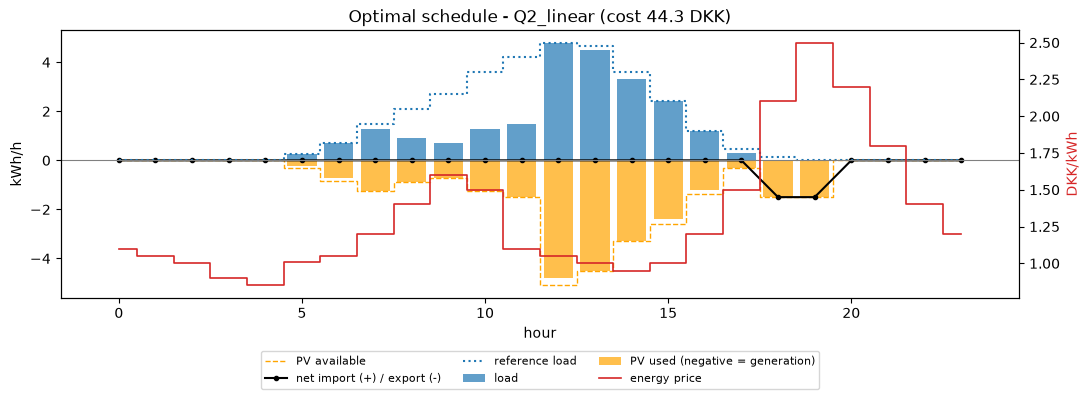

Q2(b)(iv): LINEAR COEFFICIENT SWEEP


,Coefficient,Procurement [DKK],Disutility [DKK],Energy [kWh],Abs. deviation [kWh],Hours at bounds,Objective [DKK],Above-reference hours
0,0.100,-1.470,3.2340,0.00,32.34,24,1.7640,0
1,0.500,-1.470,16.1700,0.00,32.34,24,14.7000,0
2,1.000,-1.470,32.3400,0.00,32.34,24,30.8700,0
3,1.405,-1.470,45.4377,0.00,32.34,24,43.9677,0
4,1.410,31.101,13.0284,23.10,9.24,11,44.1294,0
5,1.415,31.101,13.0746,23.10,9.24,11,44.1756,0
6,1.430,31.101,13.2132,23.10,9.24,11,44.3142,0
7,1.445,31.101,13.3518,23.10,9.24,11,44.4528,0
8,1.450,31.536,12.9630,23.40,8.94,11,44.4990,0
9,1.455,31.536,13.0077,23.40,8.94,11,44.5437,0


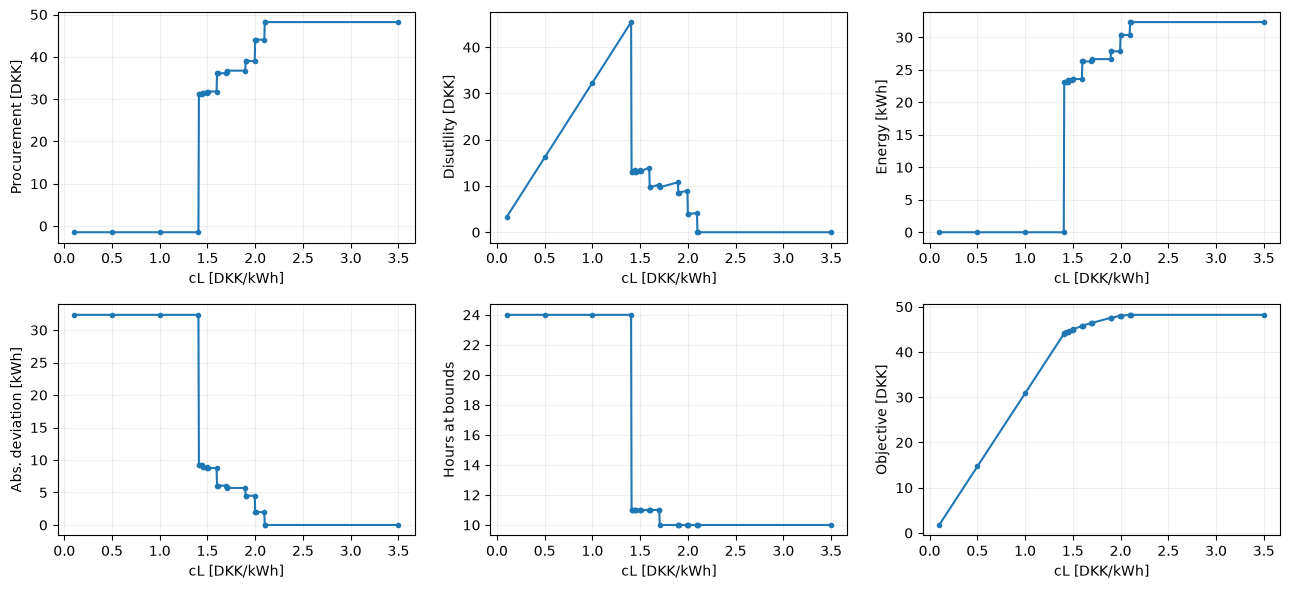

Intervals containing changes in the optimal schedule:


,From cL,To cL
0,1.405,1.410
1,1.445,1.450
2,1.495,1.500
3,1.595,1.600
4,1.695,1.700
5,1.700,1.705
6,1.895,1.900
7,1.995,2.000
8,2.095,2.100


Candidate marginal-cost thresholds: [1.41 1.45 1.5  1.6  1.7  1.7  1.9  2.   2.1 ]
PV marginal cost: 1.41 DKK/kWh


,Import price,Export price,PV available,Reference
0,1.60,0.70,0.00,0.00
1,1.55,0.65,0.00,0.00
2,1.50,0.60,0.00,0.00
3,1.40,0.50,0.00,0.00
4,1.35,0.45,0.00,0.00
5,1.51,0.61,0.30,0.24
6,1.55,0.65,0.84,0.72
7,1.70,0.80,1.26,1.50
8,1.90,1.00,0.90,2.10
9,2.10,1.20,0.72,2.70


In [7]:
# Base case.
linear_base, linear_base_row = solve_q2(
    linear_data, "linear"
)

print("Q2(b): LINEAR BASE CASE")

display(pd.DataFrame([linear_base_row]).round(4))

display(
    linear_base.hourly[
        ["reference_load", "load", "pv", "import", "export"]
    ].round(4)
)

display(plot_schedule(linear_base, linear_data))
plt.close("all")

# Effective prices.
p_imp = linear_data.energy_price + linear_data.import_tariff
p_exp = linear_data.energy_price - linear_data.export_tariff

ref = linear_data.reference_load
pv = linear_data.pv_available

# Candidate switching thresholds relevant to reference consumption.
thresholds = np.unique(np.r_[
    linear_data.pv_marginal_cost,
    p_imp[(ref > pv) & (ref > 0)],
    p_exp[
        (pv > 0)
        & (ref > 0)
        & (p_exp > linear_data.pv_marginal_cost)
    ],
])

# Sample below, at, and above the candidate thresholds.
cL_values = np.unique(np.round(np.r_[
    0.1,
    0.5,
    1.0,
    linear_data.linear_disutility,
    3.5,
    thresholds - 0.005,
    thresholds,
    thresholds + 0.005,
], 6))

print("Q2(b)(iv): LINEAR COEFFICIENT SWEEP")

linear_table, linear_runs = sweep_q2(
    linear_data, "linear", cL_values
)

# Identify sampled intervals where the hourly schedule changes.
changes = []

for previous, current in zip(
    cL_values[:-1], cL_values[1:]
):
    if not np.allclose(
        linear_runs[previous].hourly["load"],
        linear_runs[current].hourly["load"],
        atol=TOL,
        rtol=0,
    ):
        changes.append({
            "From cL": previous,
            "To cL": current,
        })

print("Intervals containing changes in the optimal schedule:")
display(pd.DataFrame(changes).round(4))

print(
    "Candidate marginal-cost thresholds:",
    thresholds.round(4),
)
print(
    "PV marginal cost:",
    linear_data.pv_marginal_cost,
    "DKK/kWh",
)

display(
    pd.DataFrame({
        "Import price": p_imp,
        "Export price": p_exp,
        "PV available": pv,
        "Reference": ref,
    }).round(4)
)

## Question 2(c): Strictly convex quadratic disutility

Base case, quadratic implementation, coefficient sweep, and numerical validation.

Q2(c): QUADRATIC BASE CASE


,Coefficient,Procurement [DKK],Disutility [DKK],Energy [kWh],Abs. deviation [kWh],Hours at bounds,Objective [DKK],Above-reference hours
0,1.0,32.5445,7.4266,22.765,9.575,13,39.971,0


,reference_load,load,pv,import,export
hour,,,,,
0,0.00,0.000,0.000,0.00,0.0
1,0.00,0.000,0.000,0.00,0.0
2,0.00,0.000,0.000,0.00,0.0
3,0.00,0.000,0.000,0.00,0.0
4,0.00,0.000,0.000,0.00,0.0
5,0.24,0.000,0.000,0.00,0.0
6,0.72,0.015,0.015,0.00,0.0
7,1.50,0.795,0.795,0.00,0.0
8,2.10,1.150,0.900,0.25,0.0


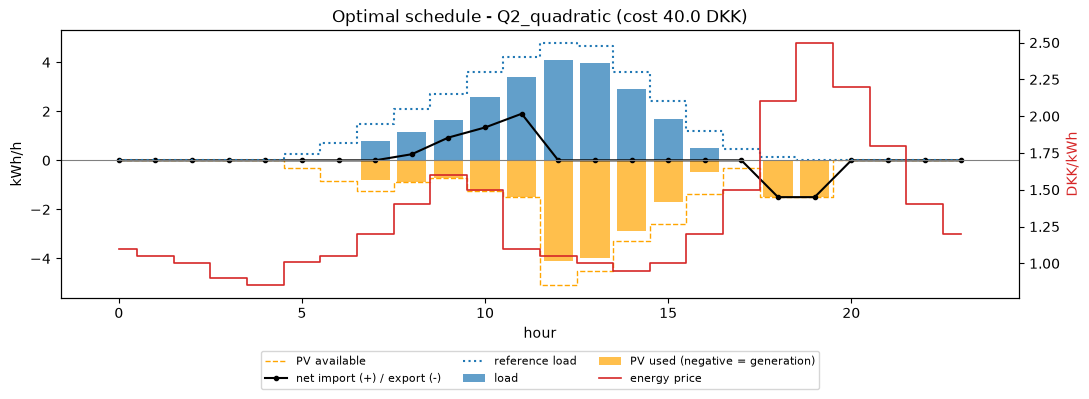

Q2(c)(iv): QUADRATIC COEFFICIENT SWEEP


,Coefficient,Procurement [DKK],Disutility [DKK],Energy [kWh],Abs. deviation [kWh],Hours at bounds,Objective [DKK],Above-reference hours
0,0.05,-1.4700,5.5237,0.0000,32.3400,24,4.0537,0
1,0.10,-1.4700,11.0473,0.0000,32.3400,24,9.5773,0
2,0.25,8.0898,15.4332,6.7800,25.5600,19,23.5230,0
3,0.50,20.8510,12.3349,15.5400,16.8000,15,33.1859,0
4,0.75,28.2319,9.3285,20.1400,12.2000,14,37.5603,0
5,1.00,32.5445,7.4266,22.7650,9.5750,13,39.9710,0
6,1.50,37.3080,5.1888,25.6867,6.6533,12,42.4968,0
7,2.00,39.8484,3.9546,27.2600,5.0800,12,43.8030,0
8,3.00,42.3817,2.7659,28.8267,3.5133,11,45.1477,0
9,5.00,44.4757,1.8221,30.1100,2.2300,11,46.2979,0


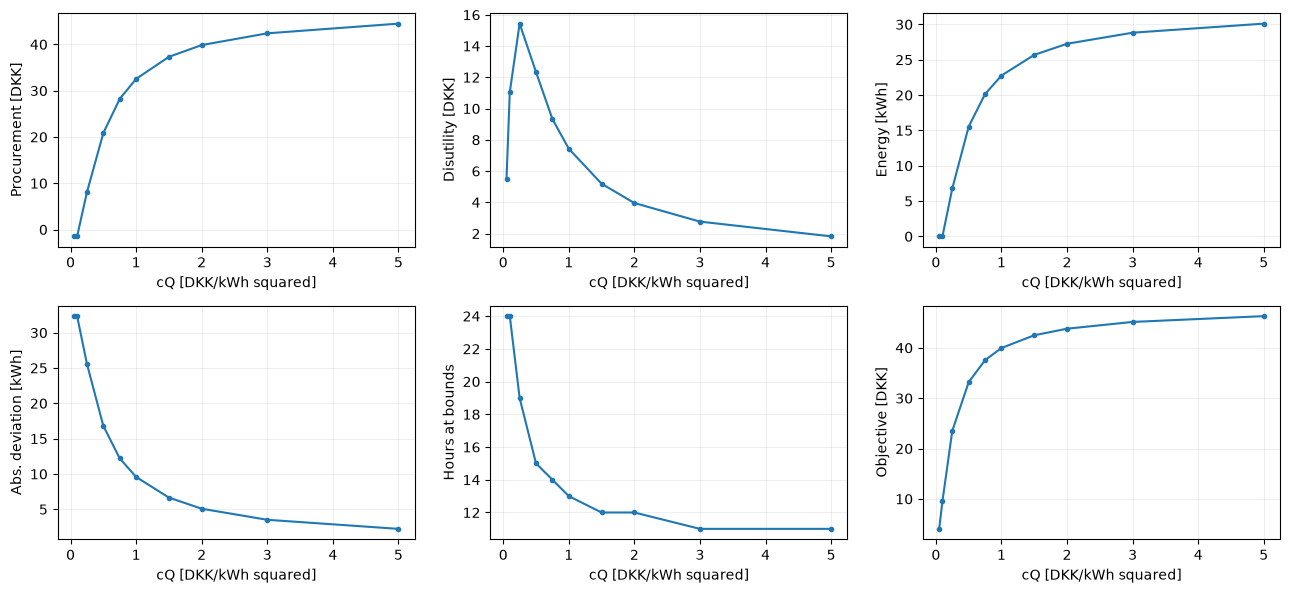

In [8]:
# Base case.
quadratic_base, quadratic_base_row = solve_q2(
    quadratic_data, "quadratic"
)

print("Q2(c): QUADRATIC BASE CASE")

display(pd.DataFrame([quadratic_base_row]).round(4))

display(
    quadratic_base.hourly[
        ["reference_load", "load", "pv", "import", "export"]
    ].round(4)
)

display(plot_schedule(quadratic_base, quadratic_data))
plt.close("all")

# Sweep from weak to strong quadratic penalties.
print("Q2(c)(iv): QUADRATIC COEFFICIENT SWEEP")

cQ_values = [
    0.05, 0.1, 0.25, 0.5, 0.75,
    1.0, 1.5, 2.0, 3.0, 5.0,
]

cQ_values = sorted(set(
    cQ_values + [quadratic_data.quadratic_disutility]
))

quadratic_table, quadratic_runs = sweep_q2(
    quadratic_data,
    "quadratic",
    cQ_values,
)

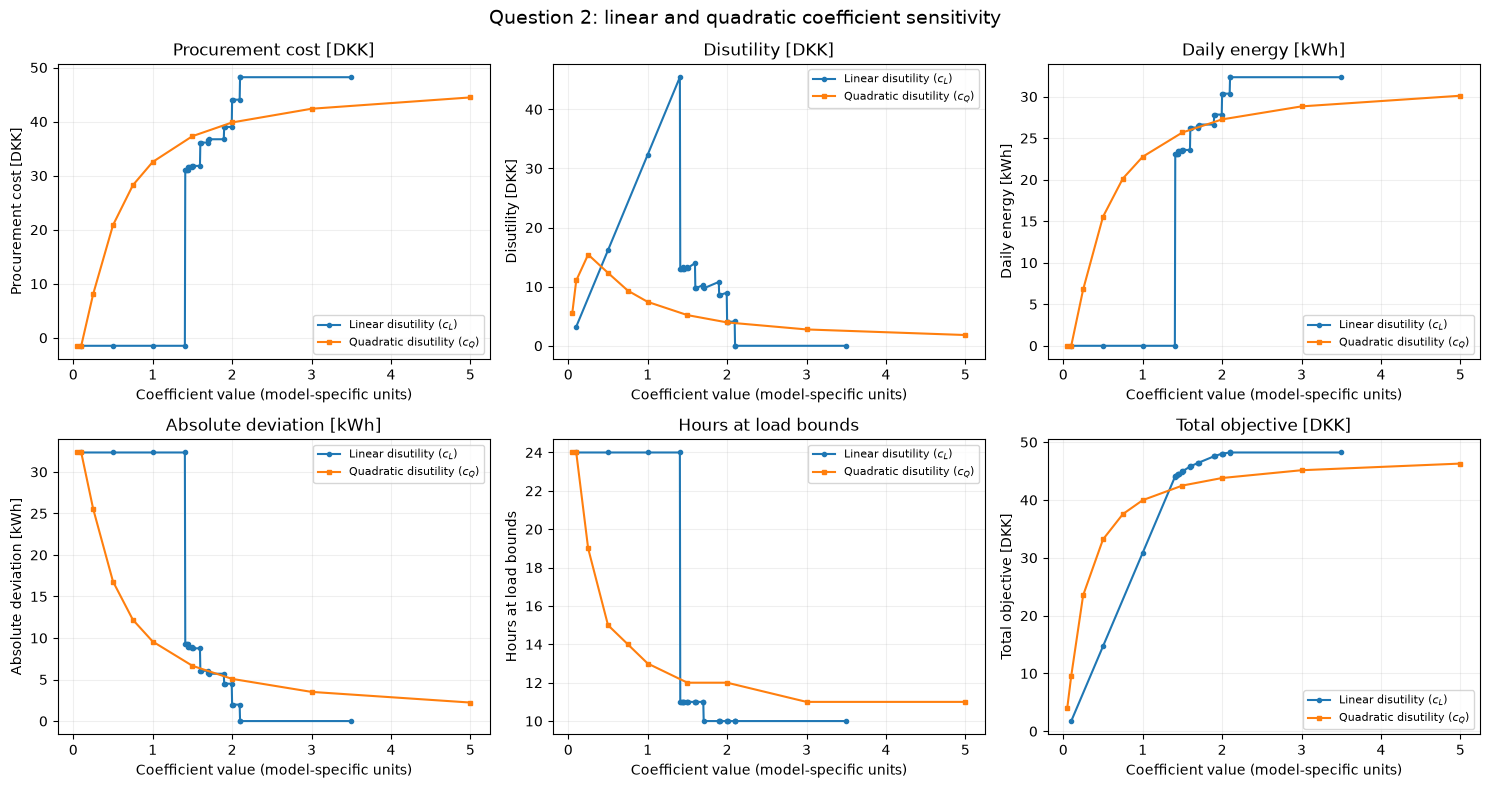

In [9]:
# Combined coefficient sensitivity plots for Q2(b) and Q2(c).
comparison_metrics = [
    ("Procurement [DKK]", "Procurement cost [DKK]"),
    ("Disutility [DKK]", "Disutility [DKK]"),
    ("Energy [kWh]", "Daily energy [kWh]"),
    ("Abs. deviation [kWh]", "Absolute deviation [kWh]"),
    ("Hours at bounds", "Hours at load bounds"),
    ("Objective [DKK]", "Total objective [DKK]"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), squeeze=False)

for ax, (column, ylabel) in zip(axes.flat, comparison_metrics):
    ax.plot(
        linear_table["Coefficient"],
        linear_table[column],
        "o-",
        markersize=3,
        label="Linear disutility ($c_L$)",
    )
    ax.plot(
        quadratic_table["Coefficient"],
        quadratic_table[column],
        "s-",
        markersize=3,
        label="Quadratic disutility ($c_Q$)",
    )
    ax.set(
        xlabel="Coefficient value (model-specific units)",
        ylabel=ylabel,
        title=ylabel,
    )
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle("Question 2: linear and quadratic coefficient sensitivity", fontsize=14)
fig.tight_layout()
q2_comparison_plot = RESULTS_DIR / "Q2" / "coefficient_sensitivity_comparison.png"
q2_comparison_plot.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(q2_comparison_plot, dpi=150)
display(fig)
plt.close(fig)

## Question 2(d): Comparison of consumer preference models

Compare the Q1 utility model, linear disutility, and quadratic disutility across weak, base, and strong preference penalties.

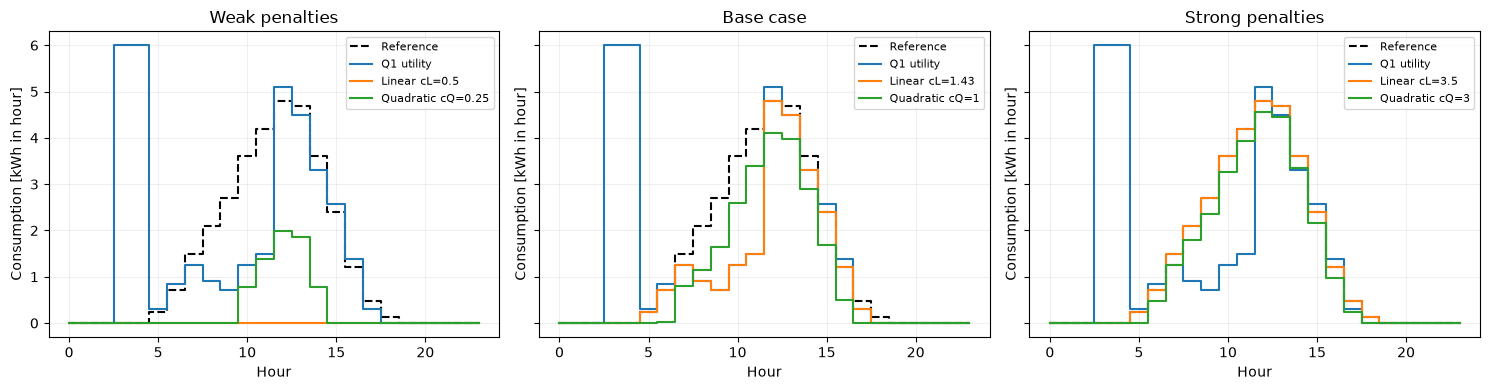

,Coefficient,Procurement [DKK],Disutility [DKK],Energy [kWh],Abs. deviation [kWh],Hours at bounds,Objective [DKK],Above-reference hours
Q1 utility,NaN,48.7854,0.0000,35.9400,22.0800,11.0,-2.6088,7.0
Linear — Weak penalties,0.50,-1.4700,16.1700,0.0000,32.3400,24.0,14.7000,0.0
Quadratic — Weak penalties,0.25,8.0898,15.4332,6.7800,25.5600,19.0,23.5230,0.0
Linear — Base case,1.43,31.1010,13.2132,23.1000,9.2400,11.0,44.3142,0.0
Quadratic — Base case,1.00,32.5445,7.4266,22.7650,9.5750,13.0,39.9710,0.0
Linear — Strong penalties,3.50,48.2160,0.0000,32.3400,0.0000,10.0,48.2160,0.0
Quadratic — Strong penalties,3.00,42.3817,2.7659,28.8267,3.5133,11.0,45.1477,0.0


In [10]:
q1_result, q1_row = solve_q2(
    load_question("Q1_caseA"),
    "utility",
    reference=linear_data.reference_load,
)

comparison_rows = {
    "Q1 utility": q1_row
}

settings = [
    ("Weak penalties", 0.5, 0.25),
    (
        "Base case",
        linear_data.linear_disutility,
        quadratic_data.quadratic_disutility,
    ),
    ("Strong penalties", 3.5, 3.0),
]

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4), sharey=True
)

for ax, (name, cL, cQ) in zip(axes, settings):
    comparison_rows[f"Linear — {name}"] = (
        linear_table.loc[
            np.isclose(linear_table["Coefficient"], cL)
        ].iloc[0].to_dict()
    )

    comparison_rows[f"Quadratic — {name}"] = (
        quadratic_table.loc[
            np.isclose(quadratic_table["Coefficient"], cQ)
        ].iloc[0].to_dict()
    )

    ax.step(
        linear_data.hours,
        linear_data.reference_load,
        where="mid",
        color="black",
        linestyle="--",
        label="Reference",
    )

    for label, result in [
        ("Q1 utility", q1_result),
        (f"Linear cL={cL:g}", linear_runs[cL]),
        (f"Quadratic cQ={cQ:g}", quadratic_runs[cQ]),
    ]:
        ax.step(
            result.hourly.index,
            result.hourly["load"],
            where="mid",
            label=label,
        )

    ax.set(
        title=name,
        xlabel="Hour",
        ylabel="Consumption [kWh in hour]",
    )
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

fig.tight_layout()
display(fig)
plt.close(fig)

display(
    pd.DataFrame(comparison_rows).T.round(4)
)

# Question 3



## Question 3(d-e): Minimum-energy model implementation and base-case comparison

Solve the integrated minimum-energy quadratic model and compare it with the unconstrained Question 2(c) consumer.

,Question 3
status,OPTIMAL
objective [DKK],63.311285
minimum daily energy [kWh],40.0
scheduled daily energy [kWh],40.0
dual mu [DKK/kWh],2.368696


,price,pv_available,reference_load,import,export,load,pv,dual_balance,dual_import,dual_export,dual_pv,dual_pv_limit,dual_load_min,dual_load_max
hour,,,,,,,,,,,,,,
0,1.10,0.00,0.00,3.843478e-01,0.000000e+00,3.843478e-01,0.00,1.60,0.0,0.9,0.00,-0.19,0.000000,-0.0
1,1.05,0.00,0.00,4.093478e-01,0.000000e+00,4.093478e-01,0.00,1.55,0.0,0.9,0.00,-0.14,0.000000,-0.0
2,1.00,0.00,0.00,4.343478e-01,0.000000e+00,4.343478e-01,0.00,1.50,0.0,0.9,0.00,-0.09,0.000000,-0.0
3,0.90,0.00,0.00,4.843478e-01,0.000000e+00,4.843478e-01,0.00,1.40,0.0,0.9,0.01,-0.00,0.000000,-0.0
4,0.85,0.00,0.00,5.093478e-01,0.000000e+00,5.093478e-01,0.00,1.35,0.0,0.9,0.06,-0.00,0.000000,-0.0
5,1.01,0.30,0.24,3.693478e-01,3.235833e-13,6.693478e-01,0.30,1.51,0.0,0.9,0.00,-0.10,0.000000,-0.0
6,1.05,0.84,0.72,2.893478e-01,3.255785e-13,1.129348e+00,0.84,1.55,0.0,0.9,0.00,-0.14,0.000000,-0.0
7,1.20,1.26,1.50,5.743478e-01,3.223211e-13,1.834348e+00,1.26,1.70,0.0,0.9,0.00,-0.29,0.000000,-0.0
8,1.40,0.90,2.10,1.434348e+00,3.216076e-13,2.334348e+00,0.90,1.90,0.0,0.9,0.00,-0.49,0.000000,-0.0


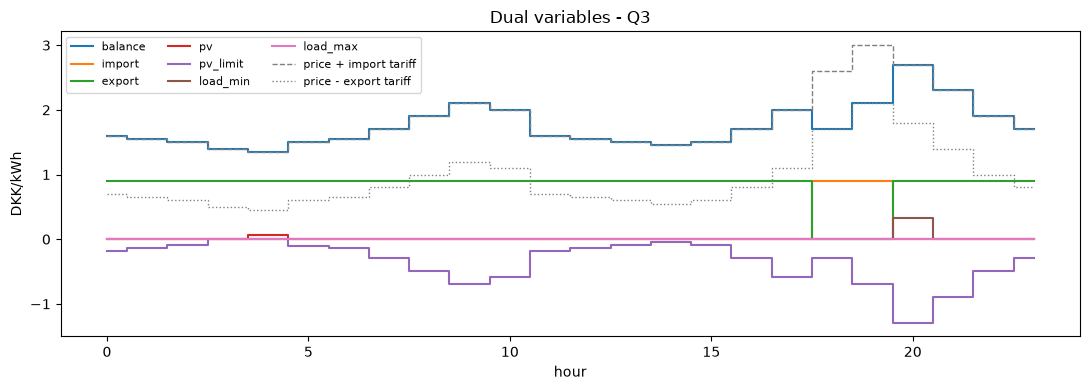

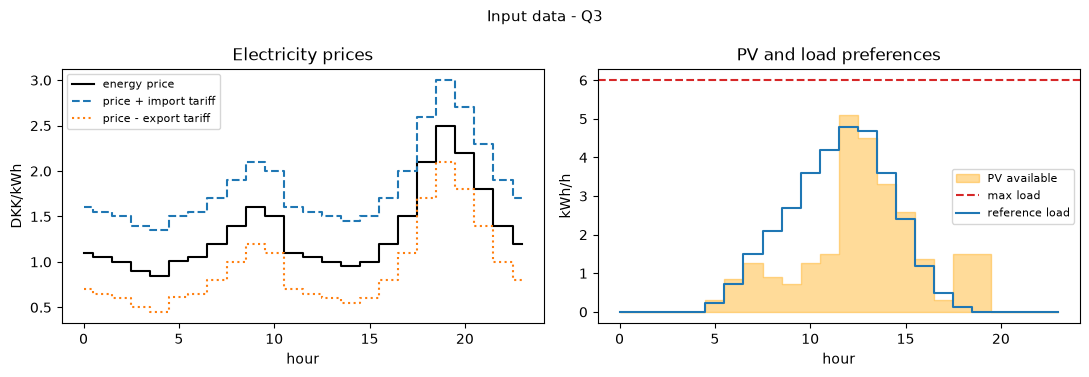

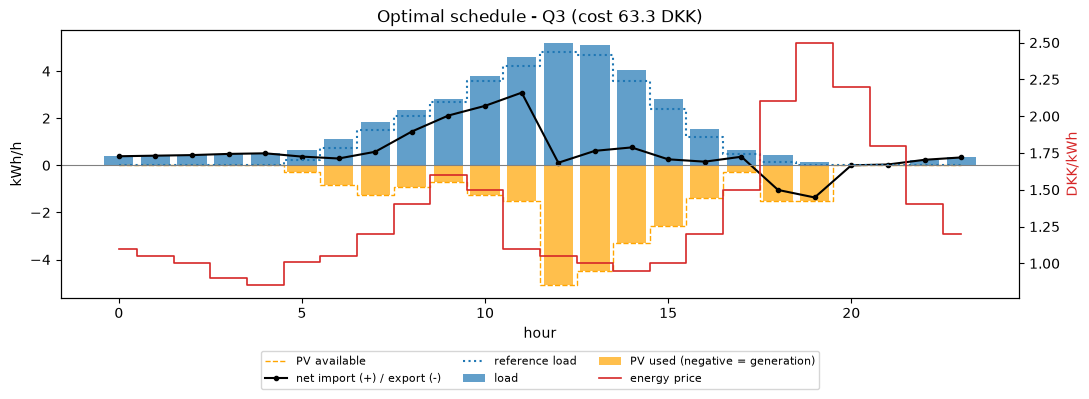

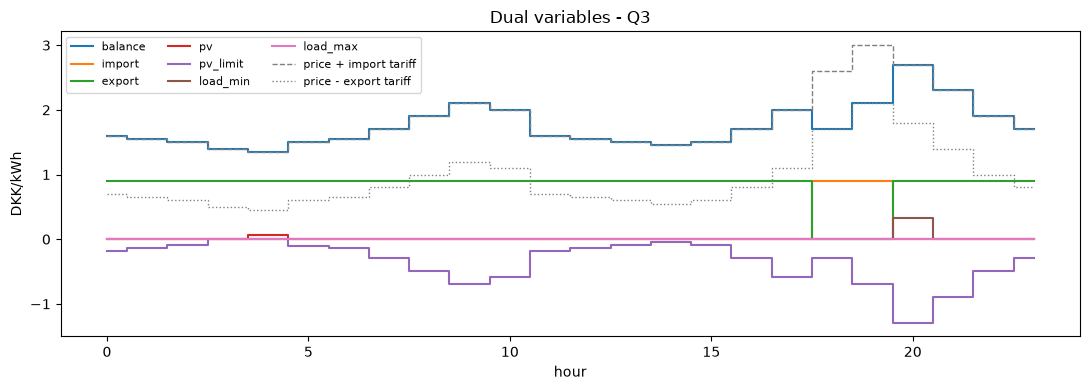

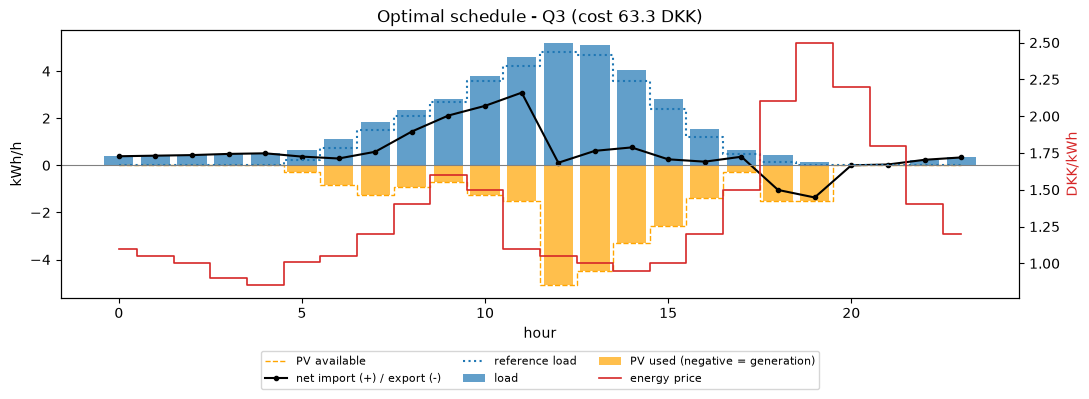

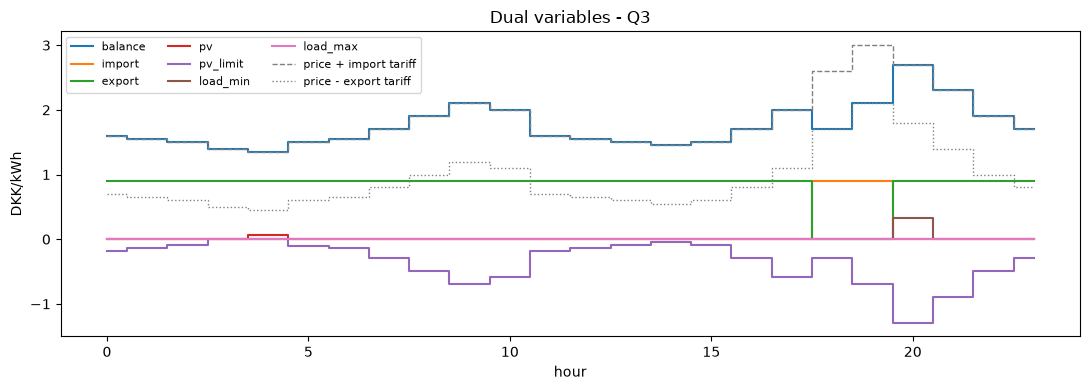

In [11]:
from src.data_loader import load_question
from src.model import MinimumEnergyQuadraticModel

q3_data = load_question("Q3")
q3_model = MinimumEnergyQuadraticModel(
    q3_data,
    minimum_daily_energy=q3_data.min_daily_energy_kWh,
).build()
q3_results = q3_model.solve()

q3_summary = pd.Series({
    "status": q3_results.status,
    "objective [DKK]": q3_results.objective,
    "minimum daily energy [kWh]": q3_data.min_daily_energy_kWh,
    "scheduled daily energy [kWh]": q3_results.hourly["load"].sum(),
    "dual mu [DKK/kWh]": q3_results.duals["min_daily_energy"],
})
display(q3_summary.to_frame("Question 3"))
display(q3_results.hourly)

q3_output_folder = RESULTS_DIR / "Q3_notebook"
q3_results.save(q3_output_folder, tag="minimum_energy_quadratic")
plot_inputs(q3_data, save_to=q3_output_folder / "inputs.png")
plot_schedule(q3_results, q3_data, save_to=q3_output_folder / "schedule.png")
plot_duals(q3_results, q3_data, save_to=q3_output_folder / "duals.png")

plot_schedule(q3_results, q3_data)
plot_duals(q3_results, q3_data)

## Question 3(f): Sensitivity analysis

This section studies how the solution changes when the daily energy requirement, disutility coefficient, and price spread are varied.

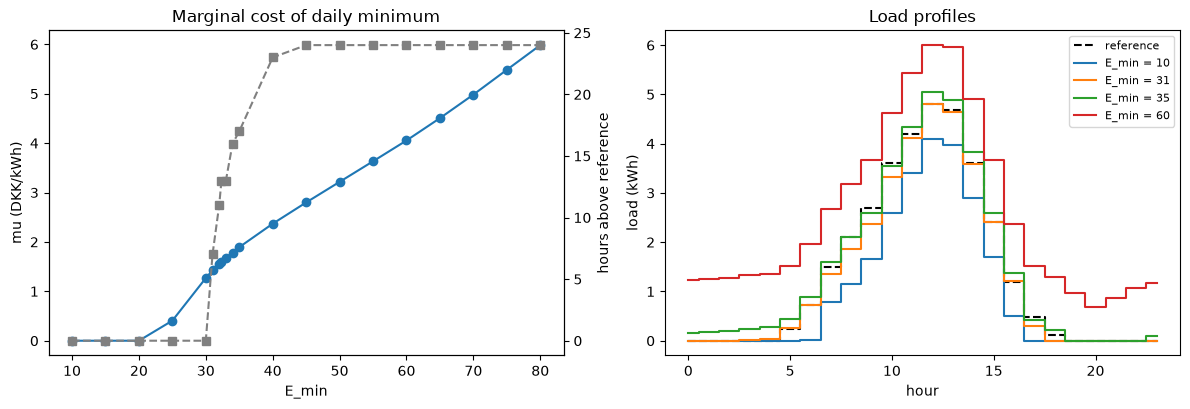

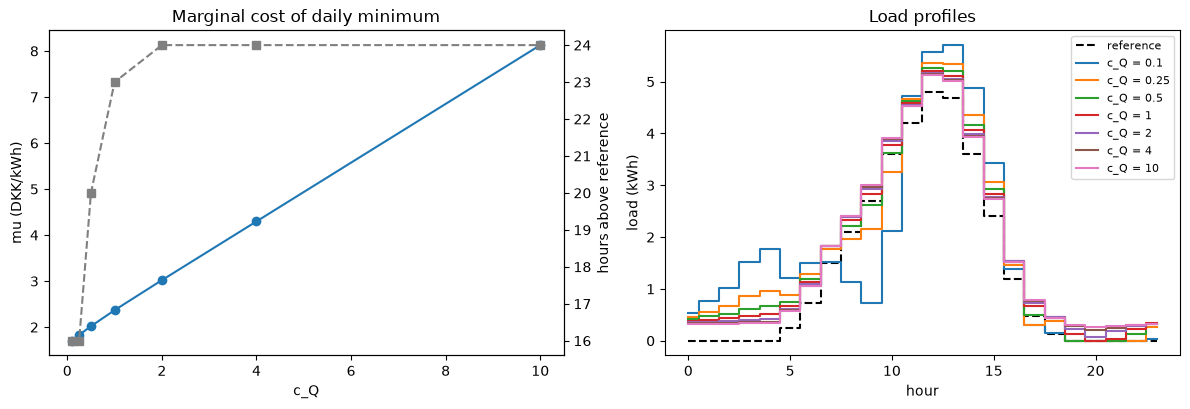

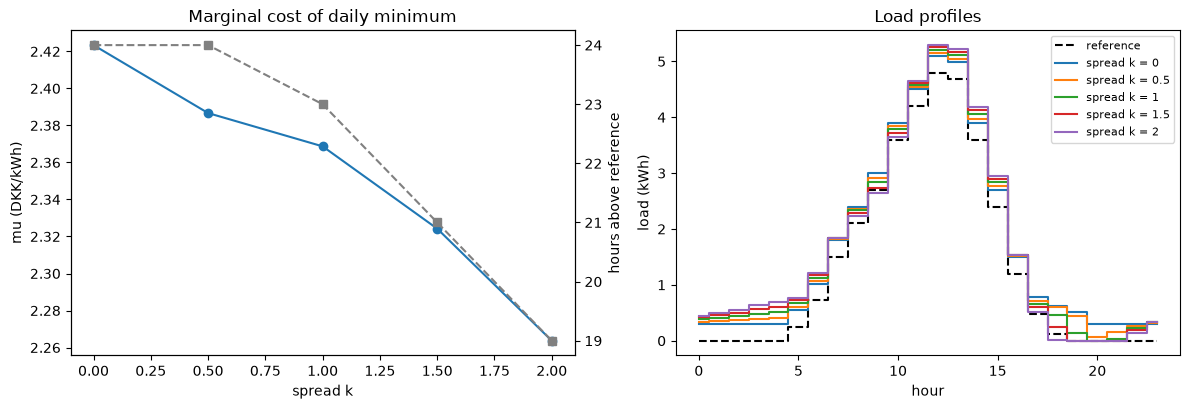

Sensitivity checks
E_min below unconstrained energy gives mu = 0: True
E_min above unconstrained energy is binding: True
mu is nondecreasing as E_min grows: True
mu matches the local objective-cost slope: True

Saved sensitivity results to results\Q3f_notebook


In [12]:
import dataclasses

q3f_output_folder = RESULTS_DIR / "Q3f_notebook"
q3f_output_folder.mkdir(parents=True, exist_ok=True)

cq0 = float(q3_data.quadratic_disutility)
em0 = float(q3_data.min_daily_energy_kWh)
reference = np.asarray(q3_data.reference_load, dtype=float)


def solve_q3_sensitivity(data, coefficient, minimum_energy):
    result = MinimumEnergyQuadraticModel(
        data,
        minimum_daily_energy=minimum_energy,
        quadratic_coefficient=coefficient,
    ).build().solve()
    load = result.hourly["load"].to_numpy()
    return {
        "E_min": minimum_energy,
        "c_Q": coefficient,
        "objective_DKK": result.objective,
        "daily_energy_kWh": load.sum(),
        "total_abs_dev_kWh": np.abs(load - reference).sum(),
        "hours_above_ref": int((load - reference > 1e-5).sum()),
        "mu": result.duals.get("min_daily_energy", 0.0),
    }, load


def run_sweep(values, make_case):
    rows = []
    loads = {}
    for value in values:
        data, coefficient, minimum_energy = make_case(value)
        row, load = solve_q3_sensitivity(data, coefficient, minimum_energy)
        row["value"] = value
        rows.append(row)
        loads[value] = load
    return pd.DataFrame(rows), loads


def plot_sensitivity(table, loads, xlabel, filename, title, show_values=None):
    figure, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(table["value"], table["mu"], "o-", label="mu")
    axes[0].set(xlabel=xlabel, ylabel="mu (DKK/kWh)", title="Marginal cost of daily minimum")
    right_axis = axes[0].twinx()
    right_axis.plot(table["value"], table["hours_above_ref"], "s--", color="gray")
    right_axis.set_ylabel("hours above reference")

    axes[1].step(range(len(reference)), reference, "k--", where="mid", label="reference")
    for value in show_values or list(loads)[::max(1, len(loads) // 4)]:
        axes[1].step(
            range(len(reference)),
            loads[value],
            where="mid",
            label=f"{xlabel} = {value:g}",
        )
    axes[1].set(xlabel="hour", ylabel="load (kWh)", title="Load profiles")
    axes[1].legend(fontsize=8)
    figure.tight_layout()
    figure.savefig(q3f_output_folder / filename, dpi=160)
    display(figure)
    plt.close(figure)


sensitivity_results = {}

em_values = sorted(set(np.round(
    np.r_[np.arange(10, 81, 5), 31, 32, reference.sum(), 33, 34, em0], 2
)))
em_values = [value for value in em_values if value <= 24 * q3_data.load_max_kWh]
em_table, em_loads = run_sweep(
    em_values,
    lambda value: (q3_data, cq0, value),
)
em_table.to_csv(q3f_output_folder / "sweep_Emin.csv", index=False)
sensitivity_results["E_min"] = em_table
plot_sensitivity(em_table, em_loads, "E_min", "sweep_Emin.png", "E_min sensitivity")

def coefficient_case(value):
    return q3_data, value, em0

cq_values = [round(cq0 * factor, 4) for factor in (0.1, 0.25, 0.5, 1, 2, 4, 10)]
cq_table, cq_loads = run_sweep(cq_values, coefficient_case)
cq_table.to_csv(q3f_output_folder / "sweep_cQ.csv", index=False)
sensitivity_results["c_Q"] = cq_table
plot_sensitivity(cq_table, cq_loads, "c_Q", "sweep_cQ.png", "c_Q sensitivity")

base_price = np.asarray(q3_data.energy_price, dtype=float)

def spread_case(value):
    spread_price = base_price.mean() + value * (base_price - base_price.mean())
    return dataclasses.replace(q3_data, energy_price=spread_price), cq0, em0

spread_values = [0.0, 0.5, 1.0, 1.5, 2.0]
spread_table, spread_loads = run_sweep(spread_values, spread_case)
spread_table.to_csv(q3f_output_folder / "sweep_spread.csv", index=False)
sensitivity_results["price spread"] = spread_table
plot_sensitivity(
    spread_table,
    spread_loads,
    "spread k",
    "sweep_spread.png",
    "Price-spread sensitivity",
    show_values=spread_values,
)

print("Sensitivity checks")
unconstrained_result, _ = solve_q3_sensitivity(q3_data, cq0, None)
unconstrained_energy = unconstrained_result["daily_energy_kWh"]
below = em_table[em_table["value"] < unconstrained_energy - 0.1]
above = em_table[em_table["value"] > unconstrained_energy + 0.1]
print("E_min below unconstrained energy gives mu = 0:", bool((below["mu"].abs() < 1e-6).all()))
print("E_min above unconstrained energy is binding:", bool(
    (abs(above["daily_energy_kWh"] - above["value"]) < 1e-4).all()
))
print("mu is nondecreasing as E_min grows:", bool((np.diff(em_table["mu"]) >= -1e-6).all()))

up, _ = solve_q3_sensitivity(q3_data, cq0, em0 + 0.01)
down, _ = solve_q3_sensitivity(q3_data, cq0, em0 - 0.01)
numerical_slope = (up["objective_DKK"] - down["objective_DKK"]) / 0.02
print("mu matches the local objective-cost slope:", abs(numerical_slope - q3_results.duals["min_daily_energy"]) < 1e-2)
print(f"\nSaved sensitivity results to {q3f_output_folder}")

## Question 3(g)(i-iii): Battery formulation, operation analysis, and implementation

The battery dynamics, terminal state-of-charge choice, simultaneous-operation discussion, and model implementation are covered by the report and the following cells.

In [13]:
from src.data_loader import load_question
from src.model import BatteryModel

# Load the Question 3 case containing the battery.
q3_battery_data = load_question("Q3_battery")

# Build and solve the battery model.
q3_battery_model = BatteryModel(
    q3_battery_data,
    minimum_daily_energy=q3_battery_data.min_daily_energy_kWh,
).build()

q3_battery_results = q3_battery_model.solve()

print(q3_battery_data.summary())
print()
print(q3_battery_results)

Case                 : Q3_battery
Consumer             : C_03_BAT
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : None
Min daily energy     : 40.0
Reference profile    : yes (32.3 kWh/day)
Disutility lin/quad  : None / 1.0
Battery              : 4.0 kWh, 1.5/1.5 kW, eta 0.95/0.95, initial SoC 2.0 kWh
Next-day forecasts   : yes

status: OPTIMAL | objective: 60.68 DKK
daily totals (kWh): import=17.6, export=3.8, load=40.0, pv=26.9
duals: {'min_daily_energy': 2.3235780238619985, 'terminal_soc': 1.7894736841676304}


In [14]:
q3_battery_hourly = q3_battery_results.hourly.copy()

# Check the hourly power balance.
q3_battery_hourly["balance_residual"] = (
    q3_battery_hourly["import"]
    + q3_battery_hourly["pv"]
    + q3_battery_hourly["discharge"]
    - q3_battery_hourly["load"]
    - q3_battery_hourly["export"]
    - q3_battery_hourly["charge"]
)

# State of charge at the beginning of each hour.
previous_soc = np.r_[
    q3_battery_data.battery_initial_soc_kWh,
    q3_battery_hourly["soc"].to_numpy()[:-1],
]

# Check the state-of-charge dynamics.
q3_battery_hourly["soc_residual"] = (
    q3_battery_hourly["soc"]
    - (
        previous_soc
        + q3_battery_data.battery_charging_efficiency
        * q3_battery_hourly["charge"]
        - q3_battery_hourly["discharge"]
        / q3_battery_data.battery_discharging_efficiency
    )
)

q3_battery_summary = pd.Series({
    "status": q3_battery_results.status,
    "objective [DKK]": q3_battery_results.objective,
    "daily load [kWh]": q3_battery_hourly["load"].sum(),
    "minimum daily energy [kWh]":
        q3_battery_data.min_daily_energy_kWh,
    "daily charging [kWh]":
        q3_battery_hourly["charge"].sum(),
    "daily discharging [kWh]":
        q3_battery_hourly["discharge"].sum(),
    "initial state of charge [kWh]":
        q3_battery_data.battery_initial_soc_kWh,
    "final state of charge [kWh]":
        q3_battery_hourly["soc"].iloc[-1],
    "maximum balance residual":
        q3_battery_hourly["balance_residual"].abs().max(),
    "maximum state-of-charge residual":
        q3_battery_hourly["soc_residual"].abs().max(),
})

display(q3_battery_summary.to_frame("Q3 battery case"))

display(
    q3_battery_hourly[
        [
            "price",
            "reference_load",
            "load",
            "pv_available",
            "pv",
            "import",
            "export",
            "charge",
            "discharge",
            "soc",
        ]
    ].round(4)
)

,Q3 battery case
status,OPTIMAL
objective [DKK],60.677739
daily load [kWh],40.0
minimum daily energy [kWh],40.0
daily charging [kWh],7.474802
daily discharging [kWh],6.746009
initial state of charge [kWh],2.0
final state of charge [kWh],2.0
maximum balance residual,0.0
maximum state-of-charge residual,0.0


,price,reference_load,load,pv_available,pv,import,export,charge,discharge,soc
hour,,,,,,,,,,
0,1.10,0.00,0.3862,0.00,0.00,0.0000,0.0000,0.0000,0.3862,1.5935
1,1.05,0.00,0.3868,0.00,0.00,0.3868,0.0000,0.0000,0.0000,1.5935
2,1.00,0.00,0.4118,0.00,0.00,0.4118,0.0000,0.0000,0.0000,1.5935
3,0.90,0.00,0.4618,0.00,0.00,1.4949,0.0000,1.0331,0.0000,2.5750
4,0.85,0.00,0.4868,0.00,0.00,1.9868,0.0000,1.5000,0.0000,4.0000
5,1.01,0.24,0.6468,0.30,0.30,0.3468,0.0000,0.0000,0.0000,4.0000
6,1.05,0.72,1.1068,0.84,0.84,0.2668,0.0000,0.0000,0.0000,4.0000
7,1.20,1.50,1.8118,1.26,1.26,0.5518,0.0000,0.0000,0.0000,4.0000
8,1.40,2.10,2.3118,0.90,0.90,0.6118,0.0000,0.0000,0.8000,3.1579


Hours with simultaneous charging and discharging: []


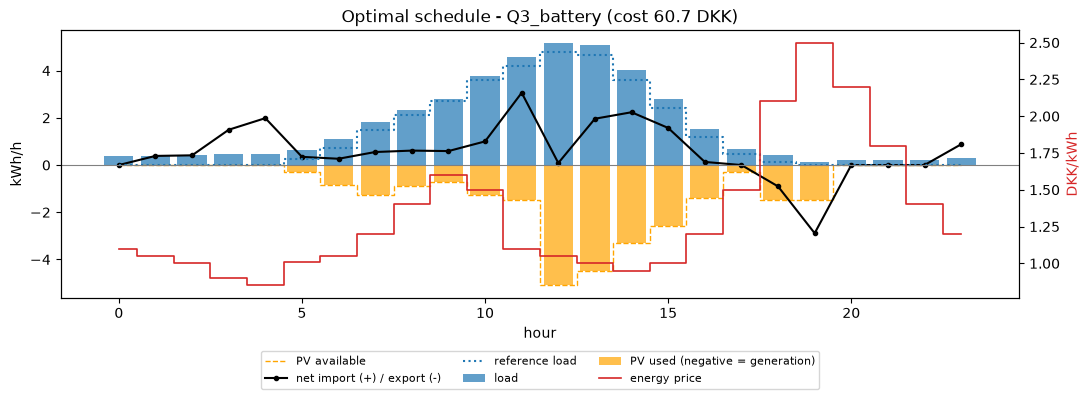

In [17]:
# Save the results.
q3g_output_folder = RESULTS_DIR / "Q3g_battery"
q3g_output_folder.mkdir(parents=True, exist_ok=True)

q3_battery_results.save(
    q3g_output_folder,
    tag="battery",
)

q3_battery_hourly.to_csv(
    q3g_output_folder / "Q3g_battery_hourly.csv",
    index_label="hour",
)

plot_schedule(
    q3_battery_results,
    q3_battery_data,
    save_to=q3g_output_folder / "schedule.png",
)

TOL = 1e-6

simultaneous_operation = (
    (q3_battery_hourly["charge"] > TOL)
    & (q3_battery_hourly["discharge"] > TOL)
)

print(
    "Hours with simultaneous charging and discharging:",
    q3_battery_hourly.index[simultaneous_operation].tolist(),
)

assert not simultaneous_operation.any()



## Question 3g(iv): Battery base-case numerical analysis

Validate the battery constraints, compare the schedules with and without storage, and calculate the battery value.

In [18]:
def q3_case_metrics(data, results):
    """Calculate the main economic and technical results for one Q3 case."""

    hourly = results.hourly
    load = hourly["load"].to_numpy()
    reference = np.asarray(data.reference_load)

    procurement_cost = (
        np.dot(
            data.energy_price + data.import_tariff,
            hourly["import"],
        )
        - np.dot(
            data.energy_price - data.export_tariff,
            hourly["export"],
        )
        + data.pv_marginal_cost * hourly["pv"].sum()
    )

    quadratic_disutility = (
        data.quadratic_disutility
        * np.square(load - reference).sum()
    )

    minimum_energy_slack = (
        load.sum() - data.min_daily_energy_kWh
    )

    # Check that the calculated cost matches the model objective.
    assert np.isclose(
        procurement_cost + quadratic_disutility,
        results.objective,
        atol=1e-5,
    )

    return {
        "Objective [DKK]": results.objective,
        "Equivalent net value [DKK]": -results.objective,
        "Procurement cost [DKK]": procurement_cost,
        "Quadratic disutility [DKK]": quadratic_disutility,
        "Daily load [kWh]": load.sum(),
        "Absolute deviation [kWh]":
            np.abs(load - reference).sum(),
        "Maximum hourly deviation [kWh]":
            np.abs(load - reference).max(),
        "Minimum-energy slack [kWh]": minimum_energy_slack,
        "Minimum-energy dual [DKK/kWh]":
            results.duals.get("min_daily_energy", np.nan),
        "Import [kWh]": hourly["import"].sum(),
        "Export [kWh]": hourly["export"].sum(),
        "PV production [kWh]": hourly["pv"].sum(),
    }


# Results without and with the battery.
no_battery_metrics = q3_case_metrics(
    q3_data,
    q3_results,
)

battery_metrics = q3_case_metrics(
    q3_battery_data,
    q3_battery_results,
)

q3g_comparison = pd.DataFrame(
    {
        "Without battery": no_battery_metrics,
        "With battery": battery_metrics,
    }
)

q3g_comparison["Difference"] = (
    q3g_comparison["With battery"]
    - q3g_comparison["Without battery"]
)

display(q3g_comparison.round(4))

# Economic value of the battery.
battery_value = (
    q3_results.objective
    - q3_battery_results.objective
)

battery_value_percent = (
    100 * battery_value / q3_results.objective
)

print(f"Battery value: {battery_value:.4f} DKK/day")
print(
    f"Objective reduction: "
    f"{battery_value_percent:.2f}%"
)

# Check for simultaneous charging and discharging.
charge = q3_battery_hourly["charge"].to_numpy()
discharge = q3_battery_hourly["discharge"].to_numpy()

simultaneous_operation = (
    (charge > 1e-6)
    & (discharge > 1e-6)
)

overlap_hours = q3_battery_hourly.index[
    simultaneous_operation
].tolist()

print(
    "Hours with simultaneous charging and discharging:",
    overlap_hours,
)

assert not simultaneous_operation.any()

# Battery losses over the day.
battery_loss = charge.sum() - discharge.sum()

print(
    f"Total charging: {charge.sum():.4f} kWh"
)
print(
    f"Total discharging: {discharge.sum():.4f} kWh"
)
print(
    f"Battery loss: {battery_loss:.4f} kWh"
)

# Save the comparison table.
q3g_comparison.to_csv(
    q3g_output_folder / "Q3g_comparison.csv"
)

,Without battery,With battery,Difference
Objective [DKK],63.3113,60.6777,-2.6335
Equivalent net value [DKK],-63.3113,-60.6777,2.6335
Procurement cost [DKK],60.3956,57.9553,-2.4402
Quadratic disutility [DKK],2.9157,2.7224,-0.1933
Daily load [kWh],40.0000,40.0000,0.0000
Absolute deviation [kWh],7.6600,7.6600,0.0000
Maximum hourly deviation [kWh],0.5093,0.4868,-0.0226
Minimum-energy slack [kWh],0.0000,0.0000,0.0000
Minimum-energy dual [DKK/kWh],2.3687,2.3236,-0.0451
Import [kWh],15.4713,17.5816,2.1103


Battery value: 2.6335 DKK/day
Objective reduction: 4.16%
Hours with simultaneous charging and discharging: []
Total charging: 7.4748 kWh
Total discharging: 6.7460 kWh
Battery loss: 0.7288 kWh


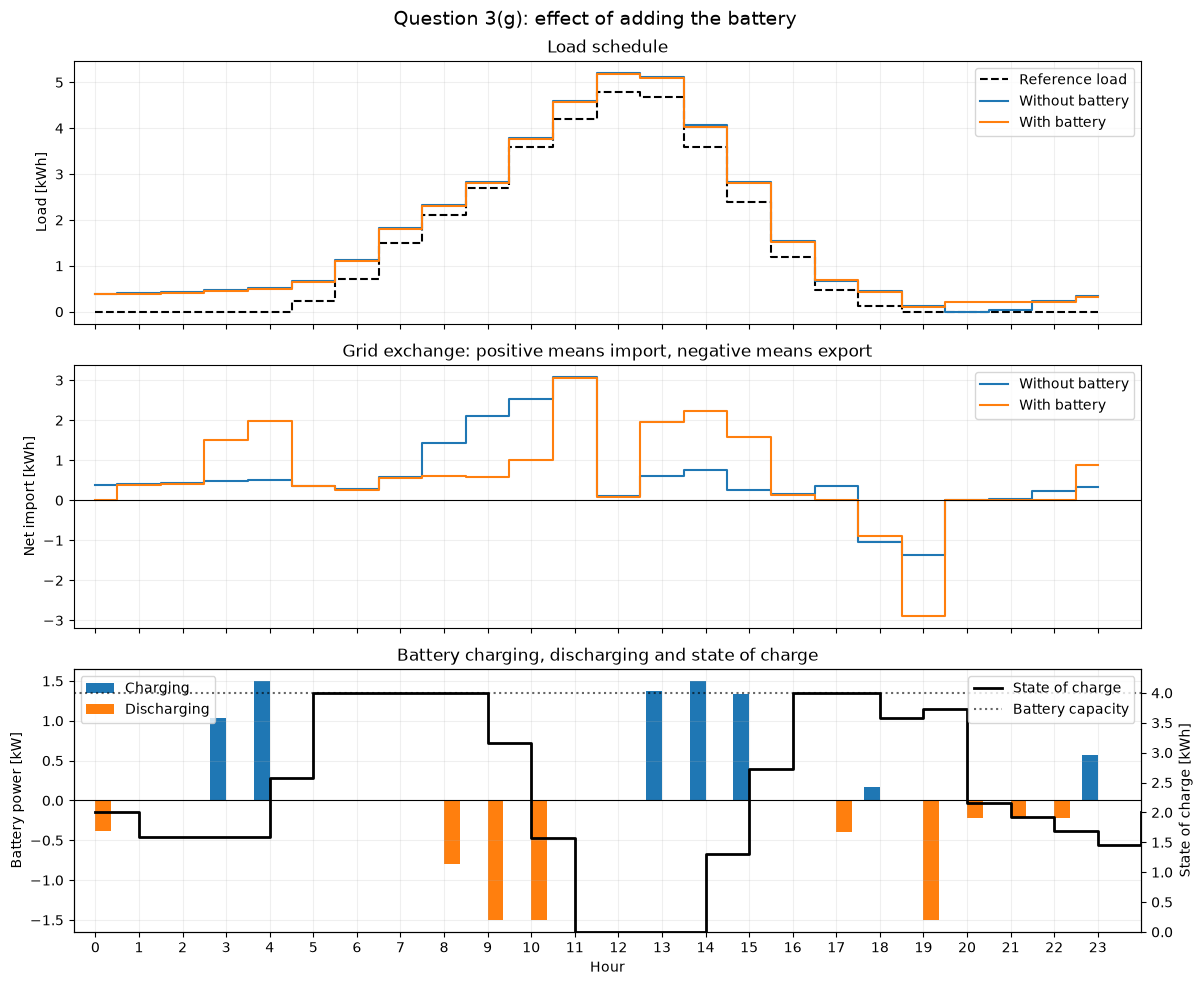

Figure saved to results\Q3g_battery\Q3g_battery_comparison.png


In [19]:
hours = np.arange(q3_battery_data.n_hours)

no_battery_hourly = q3_results.hourly
with_battery_hourly = q3_battery_results.hourly

no_battery_net_import = (
    no_battery_hourly["import"]
    - no_battery_hourly["export"]
)

with_battery_net_import = (
    with_battery_hourly["import"]
    - with_battery_hourly["export"]
)

# Include the initial state of charge before hour 0.
soc_path = np.r_[
    q3_battery_data.battery_initial_soc_kWh,
    with_battery_hourly["soc"].to_numpy(),
]

soc_time = np.arange(q3_battery_data.n_hours + 1)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 10),
    sharex=True,
)

# --------------------------------------------------------------
# 1) Load schedules
# --------------------------------------------------------------
axes[0].step(
    hours,
    q3_battery_data.reference_load,
    where="mid",
    color="black",
    linestyle="--",
    label="Reference load",
)

axes[0].step(
    hours,
    no_battery_hourly["load"],
    where="mid",
    label="Without battery",
)

axes[0].step(
    hours,
    with_battery_hourly["load"],
    where="mid",
    label="With battery",
)

axes[0].set_ylabel("Load [kWh]")
axes[0].set_title("Load schedule")
axes[0].grid(alpha=0.2)
axes[0].legend()

# --------------------------------------------------------------
# 2) Net grid exchange
# --------------------------------------------------------------
axes[1].step(
    hours,
    no_battery_net_import,
    where="mid",
    label="Without battery",
)

axes[1].step(
    hours,
    with_battery_net_import,
    where="mid",
    label="With battery",
)

axes[1].axhline(
    0,
    color="black",
    linewidth=0.8,
)

axes[1].set_ylabel("Net import [kWh]")
axes[1].set_title(
    "Grid exchange: positive means import, negative means export"
)
axes[1].grid(alpha=0.2)
axes[1].legend()

# --------------------------------------------------------------
# 3) Battery operation
# --------------------------------------------------------------
axes[2].bar(
    hours - 0.18,
    with_battery_hourly["charge"],
    width=0.36,
    label="Charging",
)

axes[2].bar(
    hours + 0.18,
    -with_battery_hourly["discharge"],
    width=0.36,
    label="Discharging",
)

axes[2].axhline(
    0,
    color="black",
    linewidth=0.8,
)

axes[2].set_xlabel("Hour")
axes[2].set_ylabel("Battery power [kW]")
axes[2].set_title(
    "Battery charging, discharging and state of charge"
)
axes[2].grid(alpha=0.2)
axes[2].legend(loc="upper left")

# State of charge on the second vertical axis.
soc_axis = axes[2].twinx()

soc_axis.step(
    soc_time,
    soc_path,
    where="post",
    color="black",
    linewidth=2,
    label="State of charge",
)

soc_axis.axhline(
    q3_battery_data.battery_capacity_kWh,
    color="black",
    linestyle=":",
    alpha=0.6,
    label="Battery capacity",
)

soc_axis.set_ylabel("State of charge [kWh]")
soc_axis.set_ylim(
    0,
    1.1 * q3_battery_data.battery_capacity_kWh,
)

soc_axis.legend(loc="upper right")

axes[2].set_xticks(hours)
axes[2].set_xlim(-0.5, 24)

fig.suptitle(
    "Question 3(g): effect of adding the battery",
    fontsize=14,
)

fig.tight_layout()

comparison_figure_path = (
    q3g_output_folder / "Q3g_battery_comparison.png"
)

fig.savefig(
    comparison_figure_path,
    dpi=160,
    bbox_inches="tight",
)

display(fig)
plt.close(fig)

print(f"Figure saved to {comparison_figure_path}")

## Question 3g(v): Sensitivity analysis of battery value

Vary environmental and battery parameters independently and analyze how they affect the value of storage.

In [20]:
from dataclasses import replace


def solve_q3g_scenario(data, use_battery):
    """Solve one Q3 scenario with or without the battery."""

    if use_battery:
        model = BatteryModel(
            data,
            minimum_daily_energy=data.min_daily_energy_kWh,
        ).build()
    else:
        model = MinimumEnergyQuadraticModel(
            data,
            minimum_daily_energy=data.min_daily_energy_kWh,
        ).build()

    results = model.solve()
    model.m.dispose()

    return results


def battery_operation_metrics(results):
    """Return total battery operation and check for overlap."""

    hourly = results.hourly

    charge = hourly["charge"].to_numpy()
    discharge = hourly["discharge"].to_numpy()

    overlap = (
        (charge > 1e-6)
        & (discharge > 1e-6)
    )

    assert not overlap.any()

    return {
        "Charging [kWh]": charge.sum(),
        "Discharging [kWh]": discharge.sum(),
        "Battery loss [kWh]":
            charge.sum() - discharge.sum(),
    }

In [21]:
base_prices = np.asarray(
    q3_battery_data.energy_price,
    dtype=float,
)

mean_price = base_prices.mean()

price_spread_factors = [
    0.5,
    1.0,
    1.5,
]

price_spread_rows = []

for factor in price_spread_factors:

    # Change the hourly price variation while keeping the mean fixed.
    scenario_prices = (
        mean_price
        + factor * (base_prices - mean_price)
    )

    scenario_data = replace(
        q3_battery_data,
        energy_price=scenario_prices,
    )

    # Solve the same scenario with and without the battery.
    without_battery = solve_q3g_scenario(
        scenario_data,
        use_battery=False,
    )

    with_battery = solve_q3g_scenario(
        scenario_data,
        use_battery=True,
    )

    operation = battery_operation_metrics(
        with_battery
    )

    price_spread_rows.append({
        "Price-spread factor": factor,
        "Minimum price [DKK/kWh]":
            scenario_prices.min(),
        "Maximum price [DKK/kWh]":
            scenario_prices.max(),
        "Objective without battery [DKK]":
            without_battery.objective,
        "Objective with battery [DKK]":
            with_battery.objective,
        "Battery value [DKK/day]":
            without_battery.objective
            - with_battery.objective,
        **operation,
    })


price_spread_table = pd.DataFrame(
    price_spread_rows
)

print("Electricity-price-spread sensitivity")
display(price_spread_table.round(4))

price_spread_table.to_csv(
    q3g_output_folder
    / "Q3g_price_spread_sensitivity.csv",
    index=False,
)

Electricity-price-spread sensitivity


,Price-spread factor,Minimum price [DKK/kWh],Maximum price [DKK/kWh],Objective without battery [DKK],Objective with battery [DKK],Battery value [DKK/day],Charging [kWh],Discharging [kWh],Battery loss [kWh]
0,0.5,1.0846,1.9096,64.7514,63.7136,1.0378,5.6397,5.0899,0.5499
1,1.0,0.8500,2.5000,63.3113,60.6777,2.6335,7.4748,6.7460,0.7288
2,1.5,0.6154,3.0904,60.3795,54.6656,5.7139,8.7105,7.8613,0.8493


Battery-capacity sensitivity


,Battery capacity [kWh],Initial state of charge [kWh],Objective without battery [DKK],Objective with battery [DKK],Battery value [DKK/day],Charging [kWh],Discharging [kWh],Battery loss [kWh]
0,2.0,1.0,63.3113,61.5601,1.7512,5.1035,4.6059,0.4976
1,4.0,2.0,63.3113,60.6777,2.6335,7.4748,6.7460,0.7288
2,6.0,3.0,63.3113,60.2810,3.0302,8.1366,7.3433,0.7933


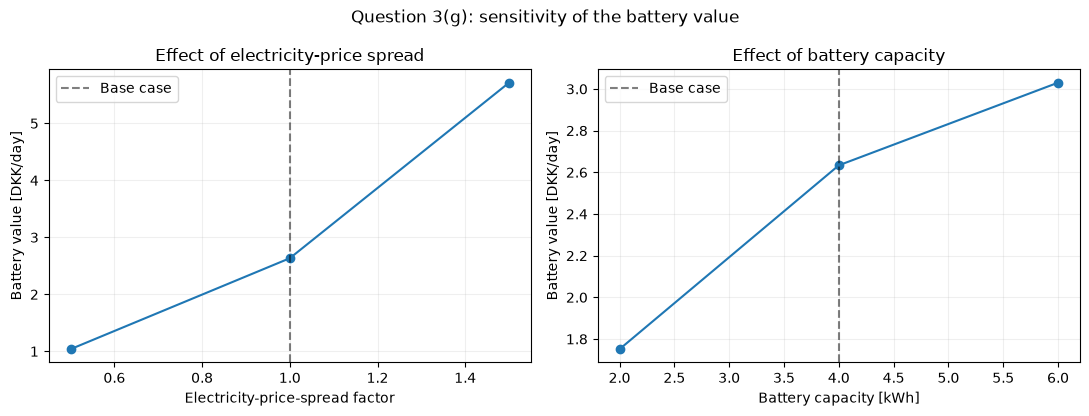

Sensitivity figure saved to results\Q3g_battery\Q3g_battery_value_sensitivity.png


In [23]:
battery_capacities = [
    2.0,
    4.0,
    6.0,
]

capacity_rows = []

# The no-battery result is unchanged when only battery capacity changes.
objective_without_battery = q3_results.objective

for capacity in battery_capacities:

    scenario_data = replace(
        q3_battery_data,
        battery_capacity_kWh=capacity,
        battery_initial_soc_kWh=0.5 * capacity,
    )

    with_battery = solve_q3g_scenario(
        scenario_data,
        use_battery=True,
    )

    operation = battery_operation_metrics(
        with_battery
    )

    capacity_rows.append({
        "Battery capacity [kWh]": capacity,
        "Initial state of charge [kWh]":
            0.5 * capacity,
        "Objective without battery [DKK]":
            objective_without_battery,
        "Objective with battery [DKK]":
            with_battery.objective,
        "Battery value [DKK/day]":
            objective_without_battery
            - with_battery.objective,
        **operation,
    })


capacity_table = pd.DataFrame(
    capacity_rows
)

print("Battery-capacity sensitivity")
display(capacity_table.round(4))

capacity_table.to_csv(
    q3g_output_folder
    / "Q3g_capacity_sensitivity.csv",
    index=False,
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4.2),
)

# Environmental parameter.
axes[0].plot(
    price_spread_table["Price-spread factor"],
    price_spread_table["Battery value [DKK/day]"],
    marker="o",
)

axes[0].axvline(
    1.0,
    color="black",
    linestyle="--",
    alpha=0.5,
    label="Base case",
)

axes[0].set(
    xlabel="Electricity-price-spread factor",
    ylabel="Battery value [DKK/day]",
    title="Effect of electricity-price spread",
)

axes[0].grid(alpha=0.2)
axes[0].legend()

# Battery parameter.
axes[1].plot(
    capacity_table["Battery capacity [kWh]"],
    capacity_table["Battery value [DKK/day]"],
    marker="o",
)

axes[1].axvline(
    q3_battery_data.battery_capacity_kWh,
    color="black",
    linestyle="--",
    alpha=0.5,
    label="Base case",
)

axes[1].set(
    xlabel="Battery capacity [kWh]",
    ylabel="Battery value [DKK/day]",
    title="Effect of battery capacity",
)

axes[1].grid(alpha=0.2)
axes[1].legend()

fig.suptitle(
    "Question 3(g): sensitivity of the battery value"
)

fig.tight_layout()

sensitivity_figure_path = (
    q3g_output_folder
    / "Q3g_battery_value_sensitivity.png"
)

fig.savefig(
    sensitivity_figure_path,
    dpi=160,
    bbox_inches="tight",
)

display(fig)
plt.close(fig)

print(
    f"Sensitivity figure saved to "
    f"{sensitivity_figure_path}"
)